# Objectifs d'apprentissage – Semaine 11

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les contraintes et les spécificités du DSP embarqué (temps réel, ressources limitées, quantification).
- **Identifier** les principales fonctionnalités de la bibliothèque CMSIS‑DSP pour les microcontrôleurs ARM Cortex‑M.
- **Simuler** en Python des fonctions CMSIS‑DSP courantes (filtres FIR, FFT, fonctions mathématiques).
- **Mettre en œuvre** un filtre FIR en virgule fixe (format Q) et analyser l'impact de la quantification.
- **Calculer** une FFT sur des données en virgule fixe et interpréter les résultats.
- **Proposer** une architecture logicielle pour une application DSP embarquée.
- **Préparer** une proposition de projet final intégrant du DSP sur STM32.

# 1. Introduction au DSP embarqué

Le traitement numérique du signal en environnement embarqué (microcontrôleurs, DSP, FPGA) présente des **contraintes spécifiques** :

- **Ressources limitées** : mémoire (RAM/ROM), puissance de calcul, consommation énergétique.
- **Temps réel** : les traitements doivent être effectués dans un temps imparti (latence, périodes d'échantillonnage).
- **Arithmétique en virgule fixe** : les microcontrôleurs sans FPU (Floating Point Unit) utilisent des entiers (Q format) pour les calculs.
- **Optimisation** : utilisation d'instructions SIMD, de bibliothèques optimisées (CMSIS‑DSP), et de techniques de réduction de la complexité.

## 1.1 La bibliothèque CMSIS‑DSP

CMSIS‑DSP (Cortex Microcontroller Software Interface Standard - DSP) est une bibliothèque optimisée pour les processeurs ARM Cortex‑M. Elle fournit des fonctions pour :
- Filtres FIR et IIR (en virgule flottante et fixe).
- Transformées (FFT, DCT, etc.).
- Fonctions mathématiques (sin, cos, atan2, etc.).
- Statistiques (moyenne, variance, etc.).
- Matrices et vecteurs.

Les fonctions sont disponibles en versions `_f32` (flottant 32 bits) et `_q15`/`_q31` (virgule fixe Q15/Q31).

## 1.2 Format Q (virgule fixe)

Le format Qm.n est une représentation en virgule fixe où m bits sont consacrés à la partie entière (incluant le signe) et n bits à la partie fractionnaire. Par exemple :
- **Q15** : 1 bit de signe, 15 bits fractionnaires → valeurs entre -1 et 1, précision de 1/32768.
- **Q31** : 1 bit de signe, 31 bits fractionnaires → valeurs entre -1 et 1, précision plus fine.

En Python, on peut simuler le format Q en utilisant des entiers et des opérations de décalage.

---

# 2. Simulation de fonctions CMSIS‑DSP en Python

Nous allons simuler quelques fonctions clés de CMSIS‑DSP en Python pour comprendre leur fonctionnement sans matériel. Les implémentations Python ne seront pas optimisées, mais reproduiront les résultats numériques attendus.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


## 2.1 Conversion Q15

Simulons la conversion float ↔ Q15.

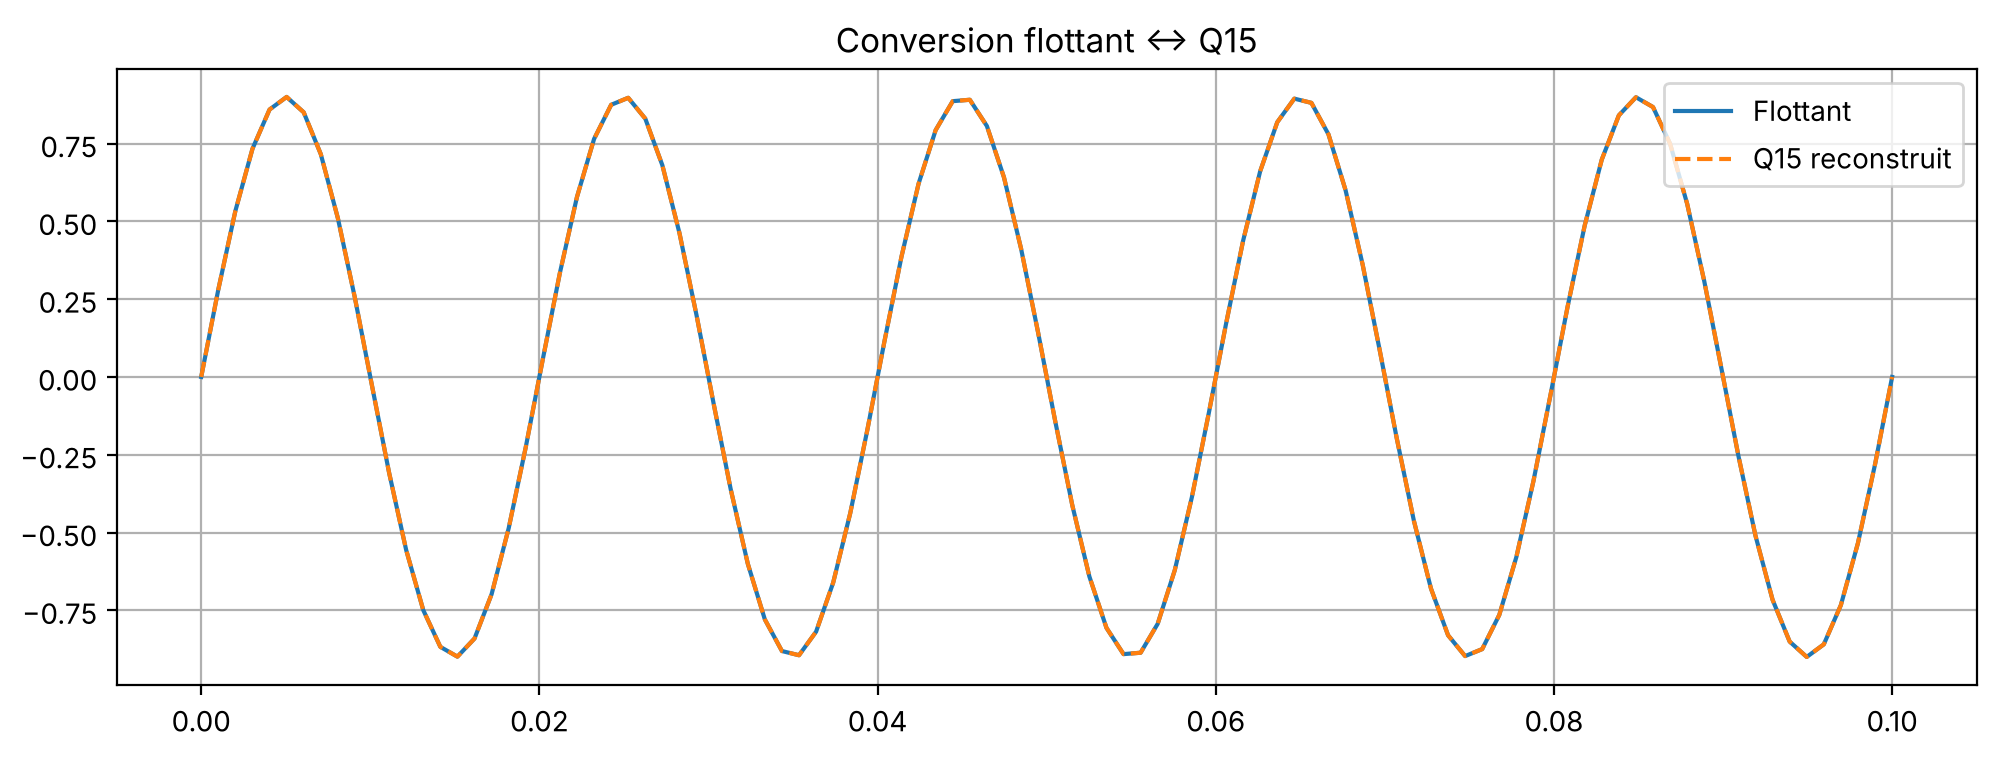

In [2]:
def float_to_q15(x):
    """Convertit un flottant (dans [-1, 1]) en entier Q15 (int16)."""
    x_sat = np.clip(x, -1.0, 1.0)
    return np.round(x_sat * 32767).astype(np.int16)

def q15_to_float(x_q):
    """Convertit un entier Q15 (int16) en flottant."""
    return x_q.astype(np.float32) / 32767.0

# Exemple
t = np.linspace(0, 0.1, 100)
signal_float = 0.9 * np.sin(2*np.pi*50*t)

signal_q15 = float_to_q15(signal_float)
signal_reconstruit = q15_to_float(signal_q15)

plt.figure(figsize=(12, 4))
plt.plot(t, signal_float, label='Flottant')
plt.plot(t, signal_reconstruit, '--', label='Q15 reconstruit')
plt.legend()
plt.grid()
plt.title('Conversion flottant ↔ Q15')
plt.show()

## 2.2 Filtre FIR en Q15 (simulation de arm_fir_q15)

Nous allons simuler un filtre FIR en utilisant des opérations Q15. La fonction `arm_fir_q15` utilise des accumulateurs en Q31 pour éviter les débordements.

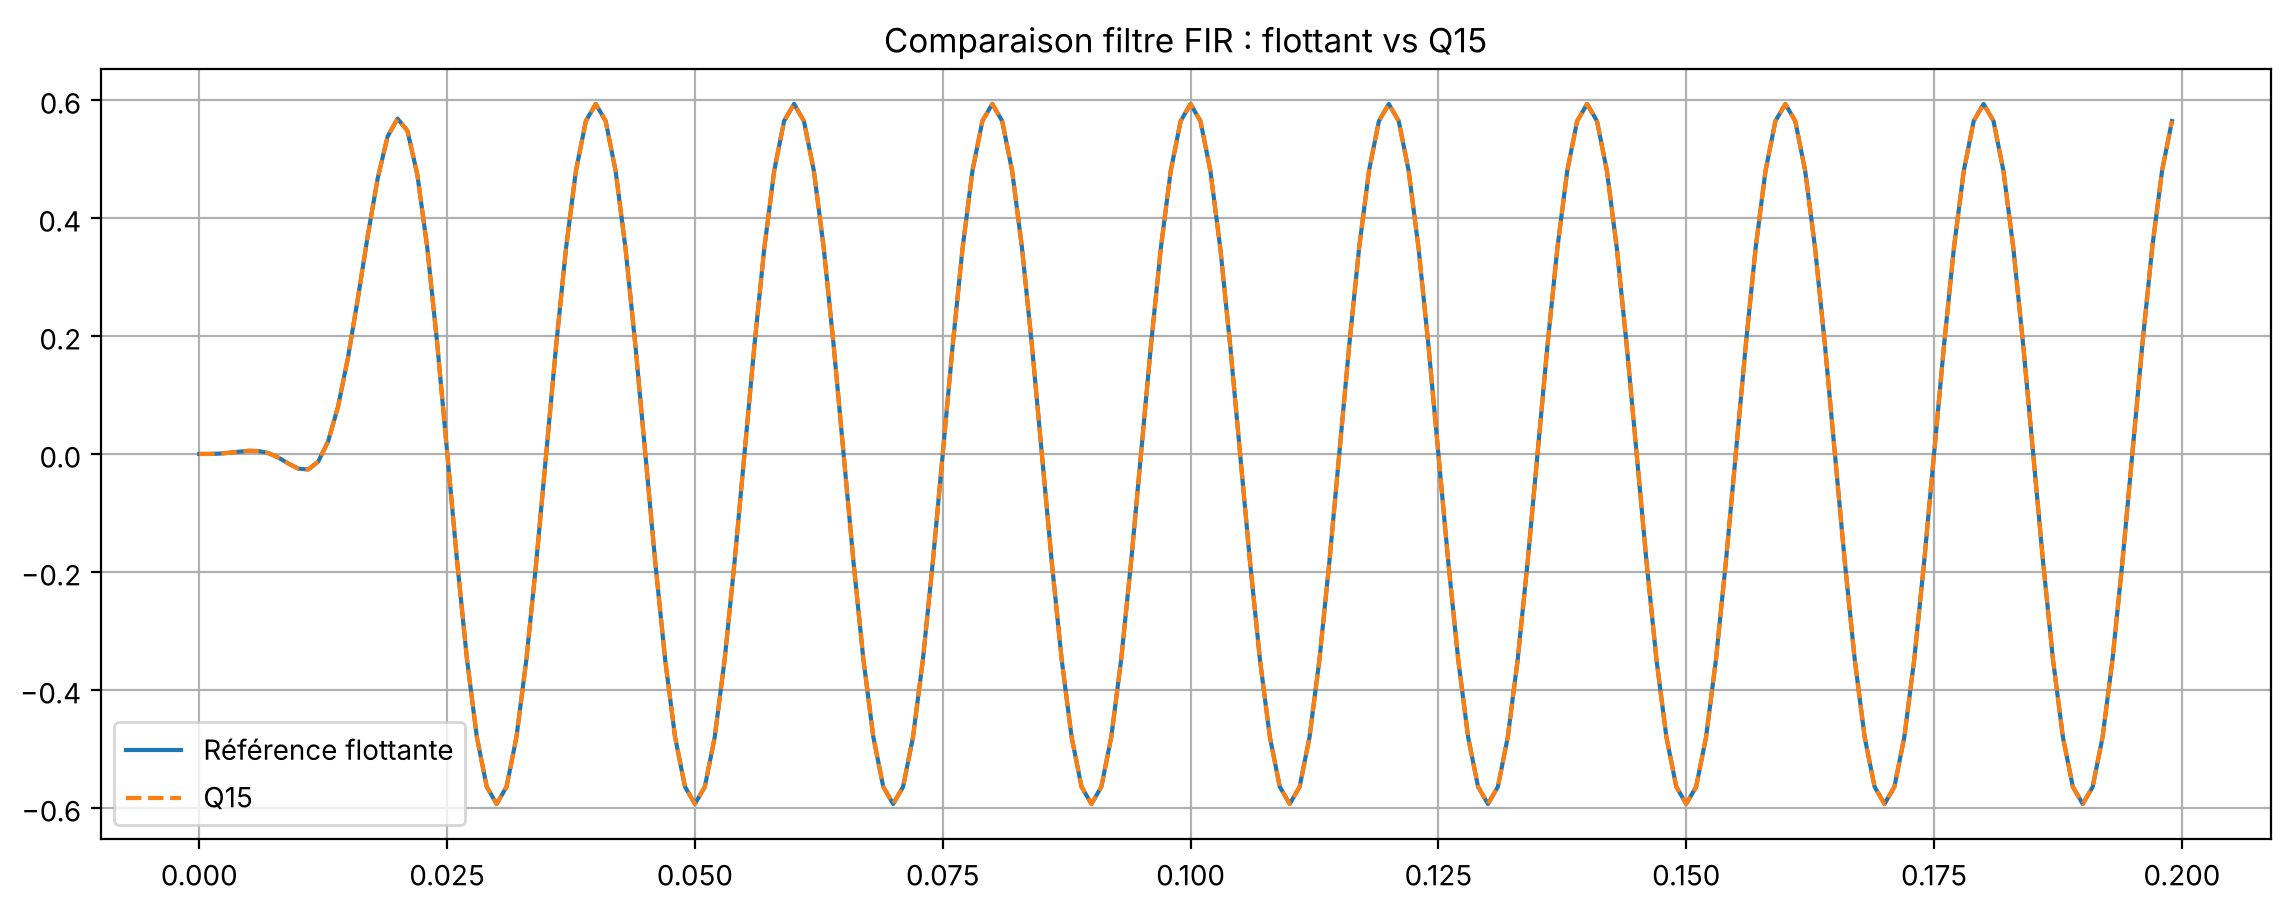

Erreur maximale : 0.000039


In [3]:
def fir_q15(x_q, b_q):
    """Simule un filtre FIR en Q15.
    x_q : entrée en Q15 (int16)
    b_q : coefficients en Q15 (int16)
    Retourne la sortie en Q15.
    """
    M = len(b_q)
    N = len(x_q)
    y_q = np.zeros(N, dtype=np.int16)
    # Buffer d'état (en Q15)
    state = np.zeros(M, dtype=np.int16)
    for n in range(N):
        # Mise à jour du buffer (décalage)
        state[1:] = state[:-1]
        state[0] = x_q[n]
        # Accumulateur 64 bits (Q34.30 comme arm_fir_q15) : 31 produits Q30 dépasseraient un int32
        acc = np.int64(0)
        for k in range(M):
            acc += np.int64(state[k]) * np.int64(b_q[k])
        # On décale de 15 pour repasser en Q15 (car produit de deux Q15 donne Q30, on ramène en Q15)
        # Attention : arrondi
        acc = (acc + (1 << 14)) >> 15
        # Saturation
        acc = np.clip(acc, -32768, 32767)
        y_q[n] = acc.astype(np.int16)
    return y_q

# Conception d'un filtre FIR passe-bas en flottant
fs = 1000
fc = 100
N_taps = 31
b_float = signal.firwin(N_taps, fc, fs=fs, window='hamming')

# Normalisation et conversion en Q15
# Les coefficients de firwin ont une somme égale à 1 : ils sont déjà dans [-1, 1] (pas de normalisation par le max,
# qui multiplierait le gain en continu par ~10 et saturerait la sortie)
b_q15 = float_to_q15(b_float)

# Signal d'entrée en flottant et conversion Q15
t = np.linspace(0, 0.2, 200, endpoint=False)
x_float = 0.6*(np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*200*t))   # amplitude max 0,9 < 1 : pas de saturation
x_q15 = float_to_q15(x_float)

# Filtrage en Q15
y_q15 = fir_q15(x_q15, b_q15)
y_float_reconstruit = q15_to_float(y_q15)

# Filtrage en flottant pour référence
y_float_ref = signal.lfilter(b_float, 1, x_float)

# Comparaison
plt.figure(figsize=(14, 5))
plt.plot(t, y_float_ref, label='Référence flottante')
plt.plot(t, y_float_reconstruit, '--', label='Q15')
plt.legend()
plt.grid()
plt.title('Comparaison filtre FIR : flottant vs Q15')
plt.show()

err = np.max(np.abs(y_float_ref - y_float_reconstruit))
print(f"Erreur maximale : {err:.6f}")

## 2.3 FFT en Q15 (simulation de arm_rfft_q15)

La FFT en Q15 nécessite une mise à l'échelle pour éviter les débordements. Nous allons simuler une FFT sur des données Q15 et comparer avec la FFT flottante.

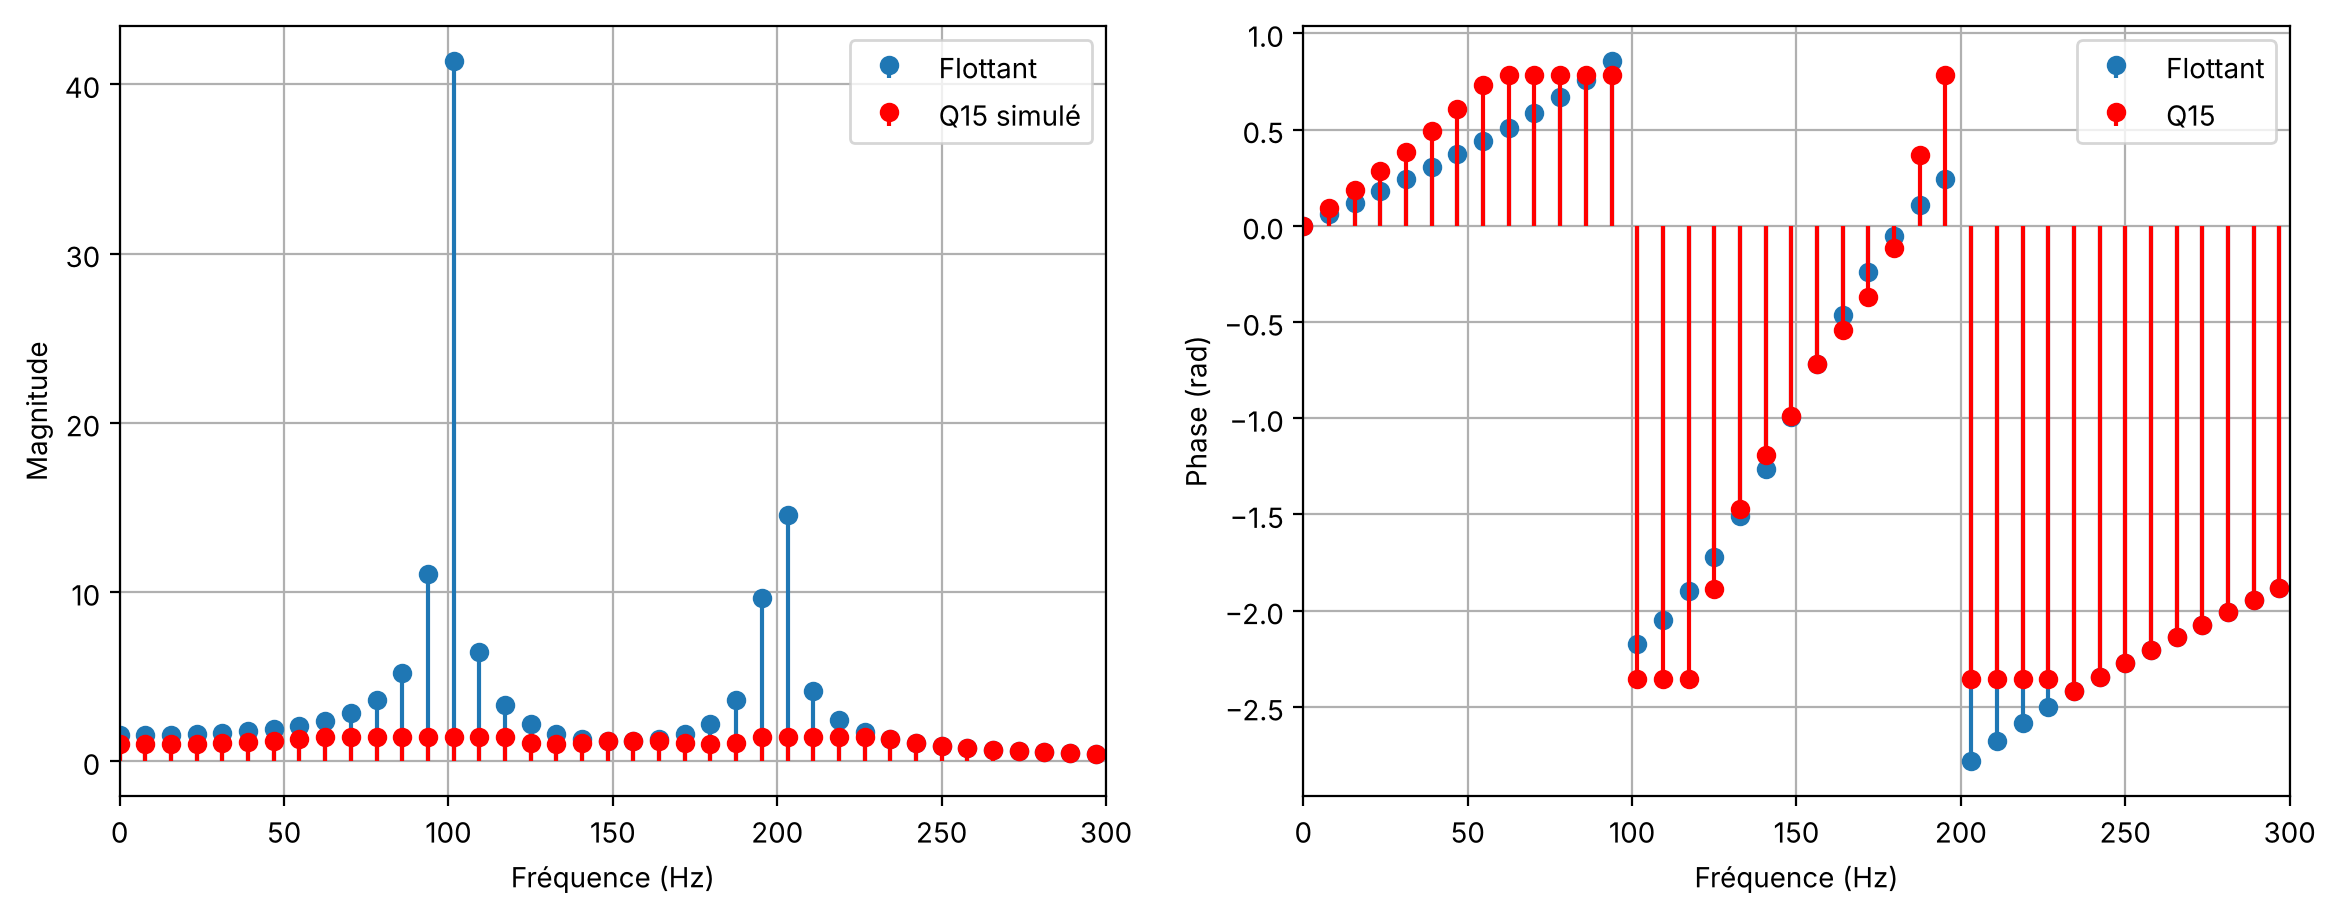

La version Q15 introduit une légère dégradation due à la quantification.


In [4]:
# Simulation d'une FFT en Q15
# Pour simplifier, on utilise la FFT flottante puis on quantifie les résultats en Q15
# Dans CMSIS-DSP, la FFT est implémentée en utilisant des rotations Q15 et des additions/soustractions avec saturation.

N_fft = 128
fs = 1000
t_fft = np.arange(N_fft) / fs
x_float = 0.7 * np.sin(2*np.pi*100*t_fft) + 0.3 * np.sin(2*np.pi*200*t_fft)

# FFT flottante
X_float = fft(x_float)[:N_fft//2]

# Conversion en Q15
x_q15 = float_to_q15(x_float)

# Simulation de la FFT Q15 : on effectue la FFT en flottant puis on quantifie les résultats
# Dans la réalité, la FFT Q15 utilise des étapes de mise à l'échelle.
X_q15_float = fft(q15_to_float(x_q15))[:N_fft//2]
# On quantifie les résultats en Q15 pour simuler la sortie de arm_rfft_q15
# La sortie de arm_rfft_q15 est généralement en Q15 pour la partie réelle et imaginaire.
X_q15_real = float_to_q15(np.real(X_q15_float))
X_q15_imag = float_to_q15(np.imag(X_q15_float))
X_q15 = q15_to_float(X_q15_real) + 1j * q15_to_float(X_q15_imag)

freqs = fftfreq(N_fft, 1/fs)[:N_fft//2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.stem(freqs, np.abs(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.abs(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15 simulé')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(freqs, np.angle(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.angle(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

print("La version Q15 introduit une légère dégradation due à la quantification.")

## 2.4 Fonctions mathématiques (sin, cos, atan2) en Q15

CMSIS‑DSP fournit des tables de recherche pour les fonctions trigonométriques en Q15. Simulons un calcul de sinus en Q15 à l'aide d'une table.

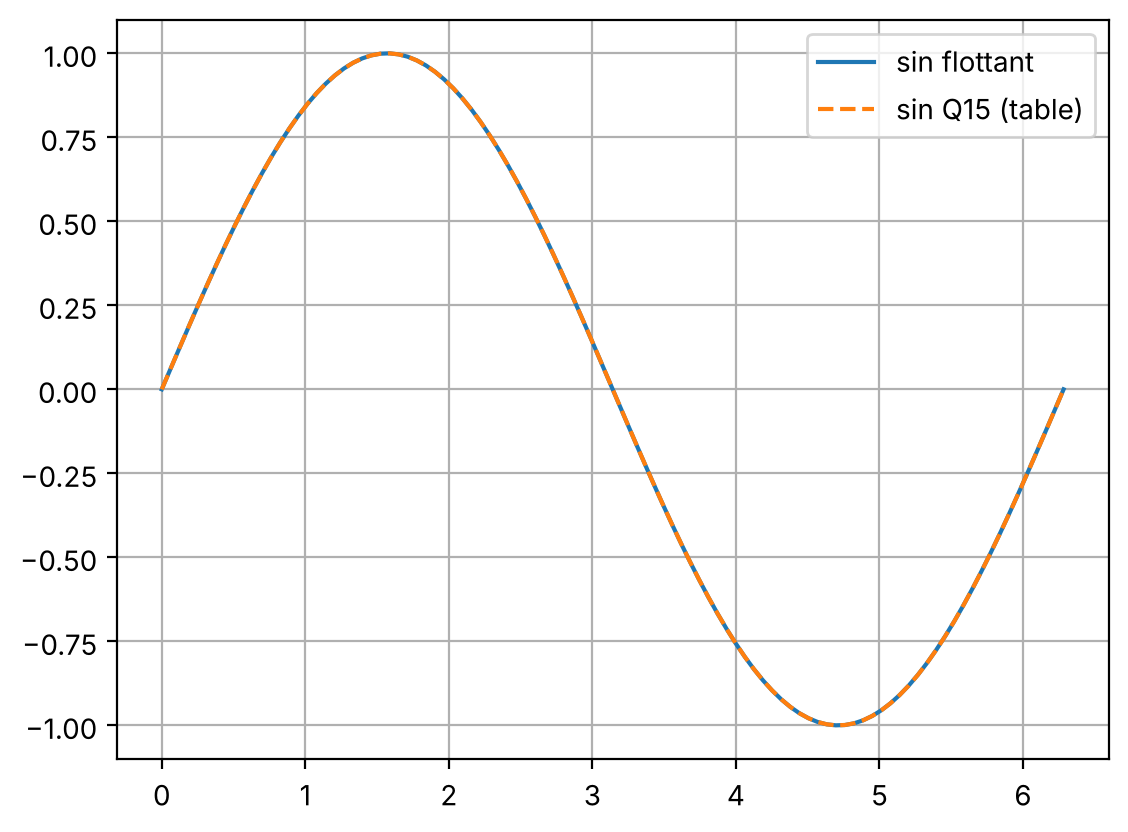

In [5]:
# Table de sinus Q15 pour 360 degrés (ou 2*pi radians)
# En pratique, la table est stockée dans la mémoire du microcontrôleur.
def sin_q15(angle_q15):
    """Simule arm_sin_q15 : angle en Q15 (0 correspond à 0 rad, 32767 correspond à 2*pi)."""
    # angle_q15 est un entier entre 0 et 32767 représentant 0 à 2*pi
    angle_q15 = int(angle_q15)   # on repasse en entier Python : le produit par 256 dépasserait la plage int16
    # On utilise une interpolation linéaire sur une table de 256 points
    n_points = 256
    table = np.sin(2*np.pi * np.arange(n_points) / n_points)
    # Convertir angle_q15 en index 0..n_points-1
    idx = (angle_q15 * n_points) // 32768
    idx = np.clip(idx, 0, n_points-1)
    # Interpolation linéaire
    frac = (angle_q15 * n_points) % 32768 / 32768.0
    val = (1-frac) * table[idx] + frac * table[(idx+1) % n_points]
    return float_to_q15(val)

# Test
angles = np.linspace(0, 2*np.pi, 100)
sin_float = np.sin(angles)
sin_q15_vals = np.array([sin_q15(float_to_q15(angle/(2*np.pi))) for angle in angles])
sin_reconst = q15_to_float(sin_q15_vals)

plt.plot(angles, sin_float, label='sin flottant')
plt.plot(angles, sin_reconst, '--', label='sin Q15 (table)')
plt.legend()
plt.grid()
plt.show()

# 3. Atelier : Mise en œuvre d'une application DSP embarquée

Nous allons simuler une application complète : un filtre anti-repliement (passe-bas) suivi d'une FFT pour analyser un signal, en utilisant des fonctions en virgule fixe. L'architecture est typique d'un système embarqué temps réel : acquisition (ADC), filtrage, FFT, puis communication ou affichage.

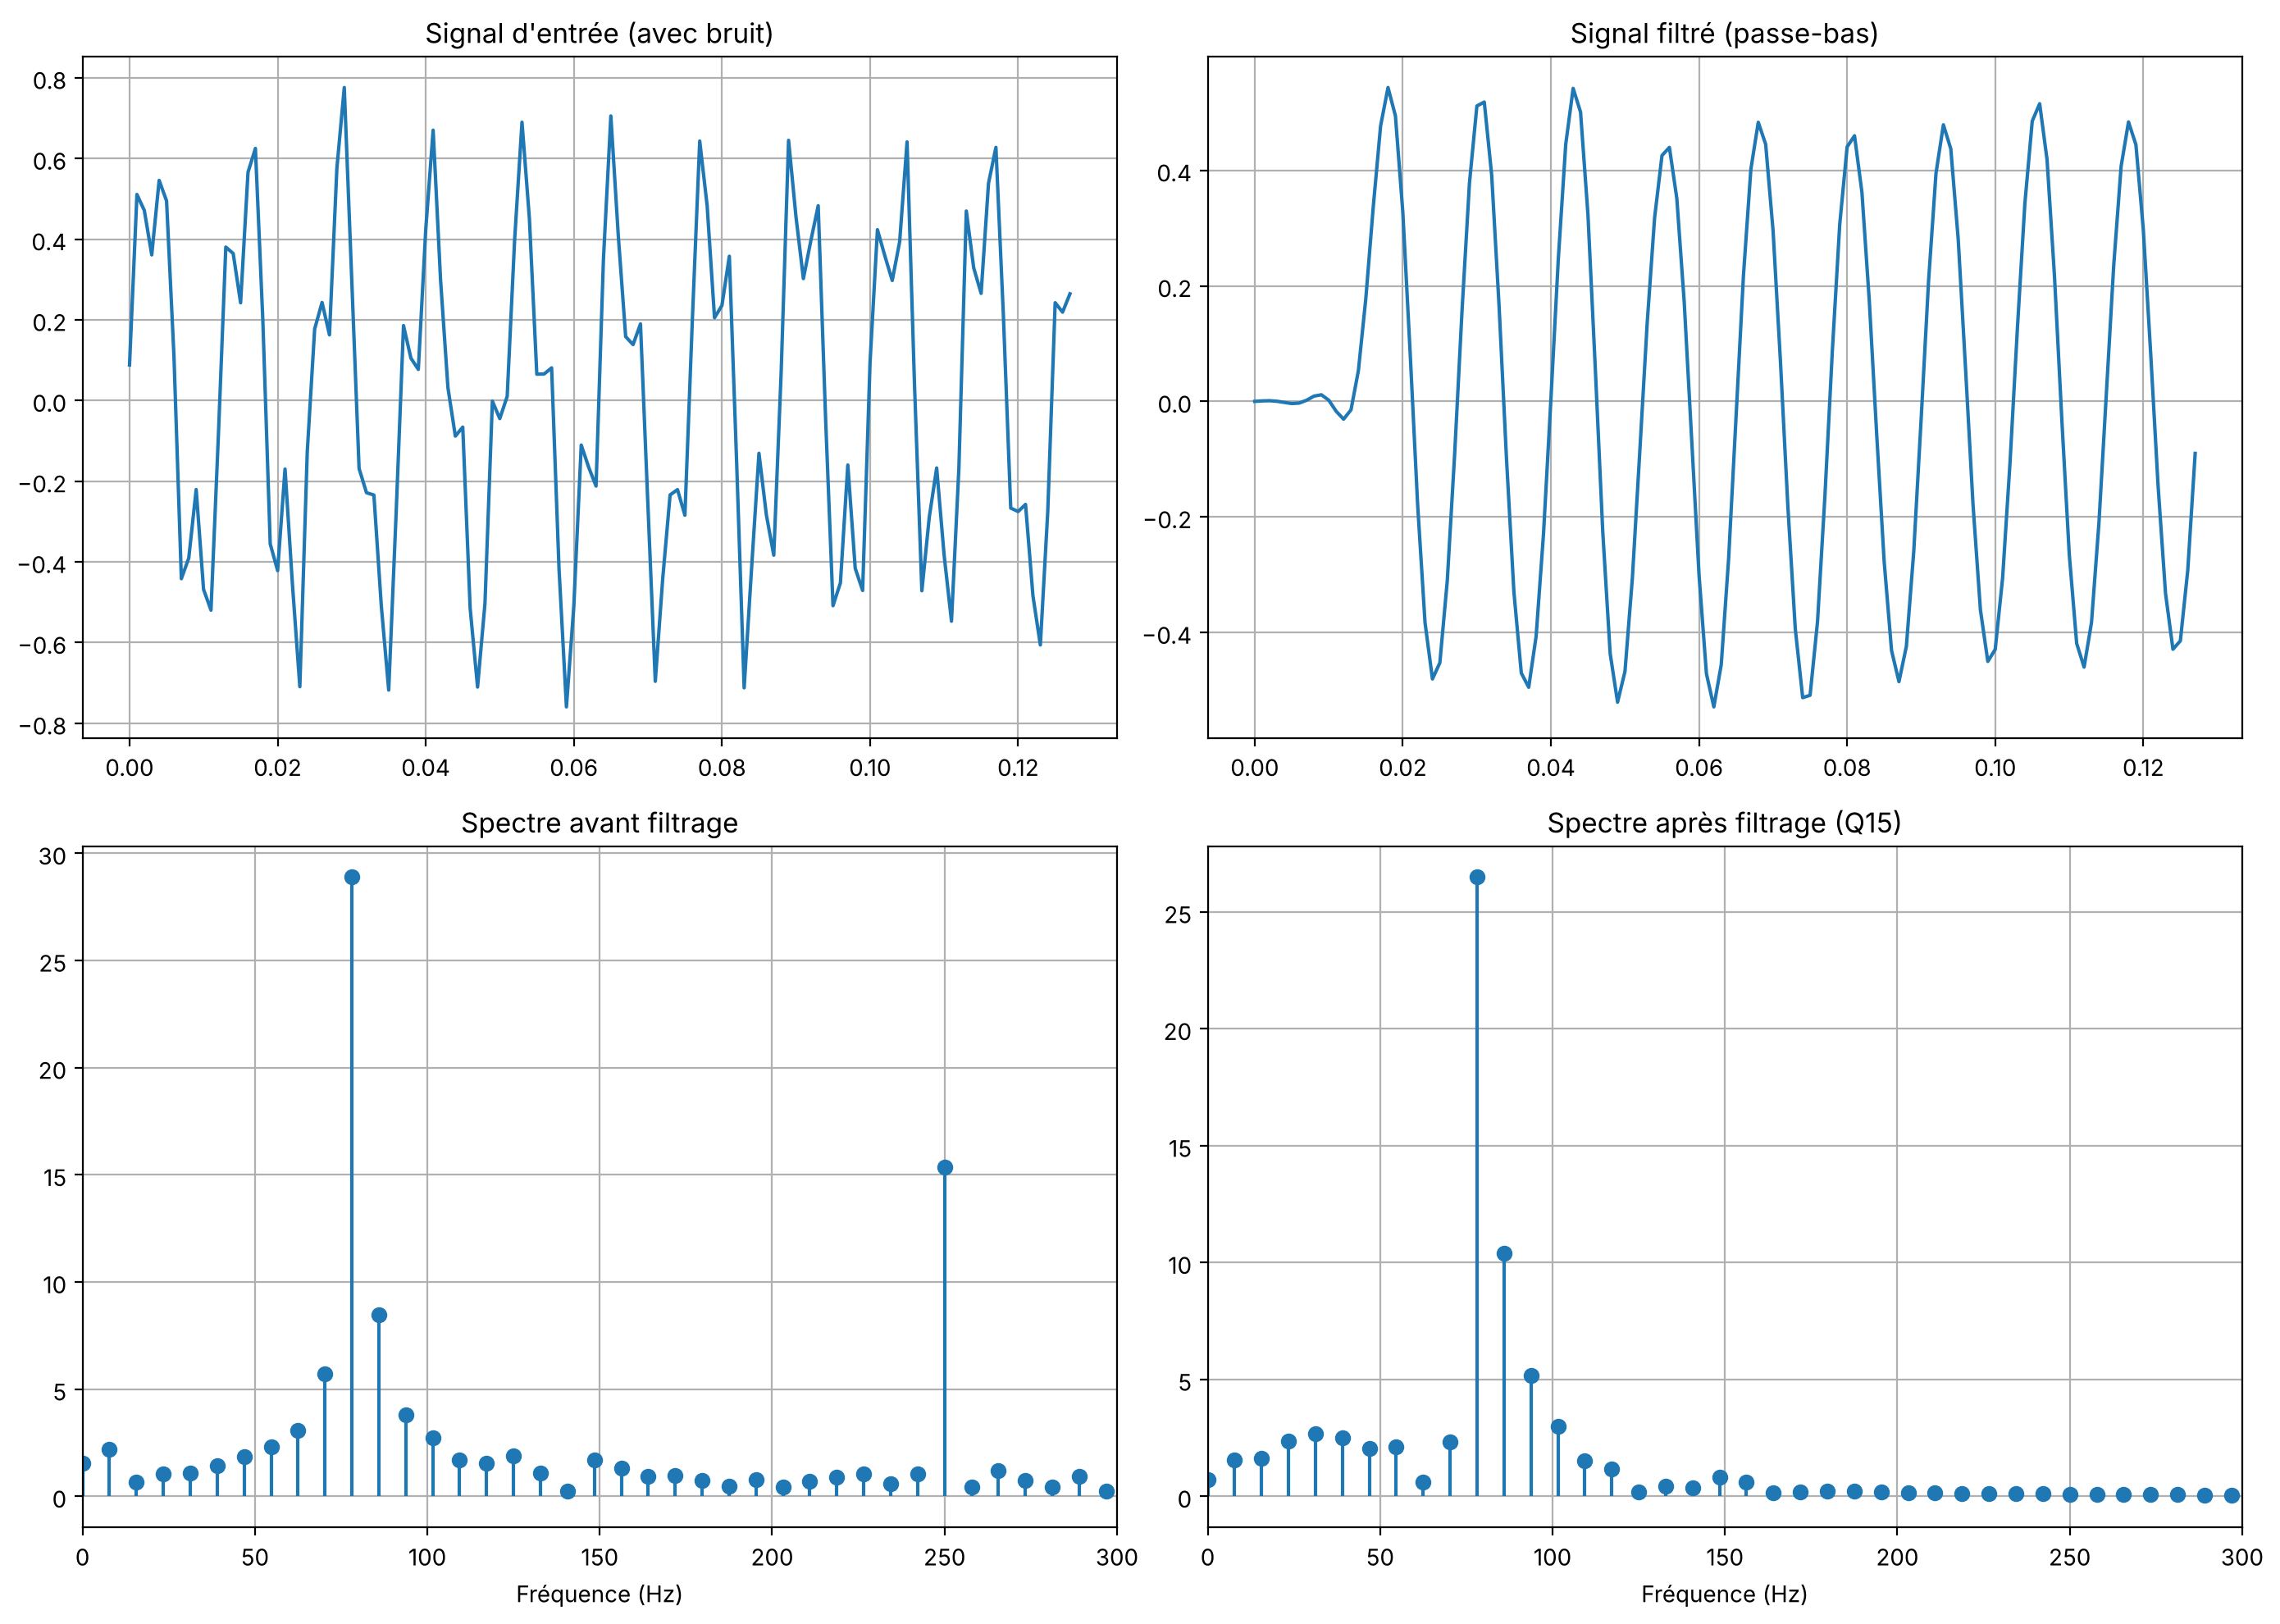

Taille du filtre : 31 coefficients en Q15
Nombre d'échantillons FFT : 128
En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.


In [6]:
# Paramètres système
fs = 1000
N_samples = 128
t = np.arange(N_samples) / fs

# Signal d'entrée simulé (mélange de fréquences)
np.random.seed(0)
x_float = 0.5*(np.sin(2*np.pi*80*t) + 0.5*np.sin(2*np.pi*250*t)) + 0.05*np.random.randn(N_samples)

# 1. Filtre anti-repliement (passe-bas en Q15)
# Conception du filtre en flottant
fc = 150
b_float = signal.firwin(31, fc, fs=fs, window='hamming')
b_q15 = float_to_q15(b_float)

# Conversion entrée en Q15
x_q15 = float_to_q15(x_float)

# Filtrage
y_q15 = fir_q15(x_q15, b_q15)
y_float = q15_to_float(y_q15)

# 2. FFT en Q15 sur le signal filtré
# (simulée comme précédemment)
X_q15_real = float_to_q15(np.real(fft(y_float)[:N_samples//2]))
X_q15_imag = float_to_q15(np.imag(fft(y_float)[:N_samples//2]))
X_q15 = q15_to_float(X_q15_real) + 1j*q15_to_float(X_q15_imag)

freqs = fftfreq(N_samples, 1/fs)[:N_samples//2]

# Visualisation
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(t, x_float)
plt.title('Signal d\'entrée (avec bruit)')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(t, y_float)
plt.title('Signal filtré (passe-bas)')
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(freqs, np.abs(fft(x_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre avant filtrage')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs, np.abs(fft(y_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre après filtrage (Q15)')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.tight_layout()
plt.show()

# Bilan des ressources simulées
print(f"Taille du filtre : {len(b_q15)} coefficients en Q15")
print(f"Nombre d'échantillons FFT : {N_samples}")
print("En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.")

# 4. Exercices – Semaine 11

## Exercice 1 – Filtre RII en Q15

1. Concevoir un filtre RII Butterworth passe-bas d'ordre 4 avec fc=100 Hz, fs=1000 Hz.
2. Convertir les coefficients en Q15 (normalisation puis quantification).
3. Implémenter une fonction `iir_q15` simulant un filtre RII en Q15 (structure directe II) en utilisant un accumulateur Q31.
4. Tester sur un signal bruité et comparer avec la version flottante.
5. Discuter de la stabilité : que se passe-t-il si l'ordre est trop élevé en Q15 ?

**Code** :

b = [0.00482 0.0193  0.02895 0.0193  0.00482]
a = [ 1.      -2.36951  2.31399 -1.05467  0.18738]
Format des coefficients : Q2.13  (a1 = -19411 -> -2.3695)


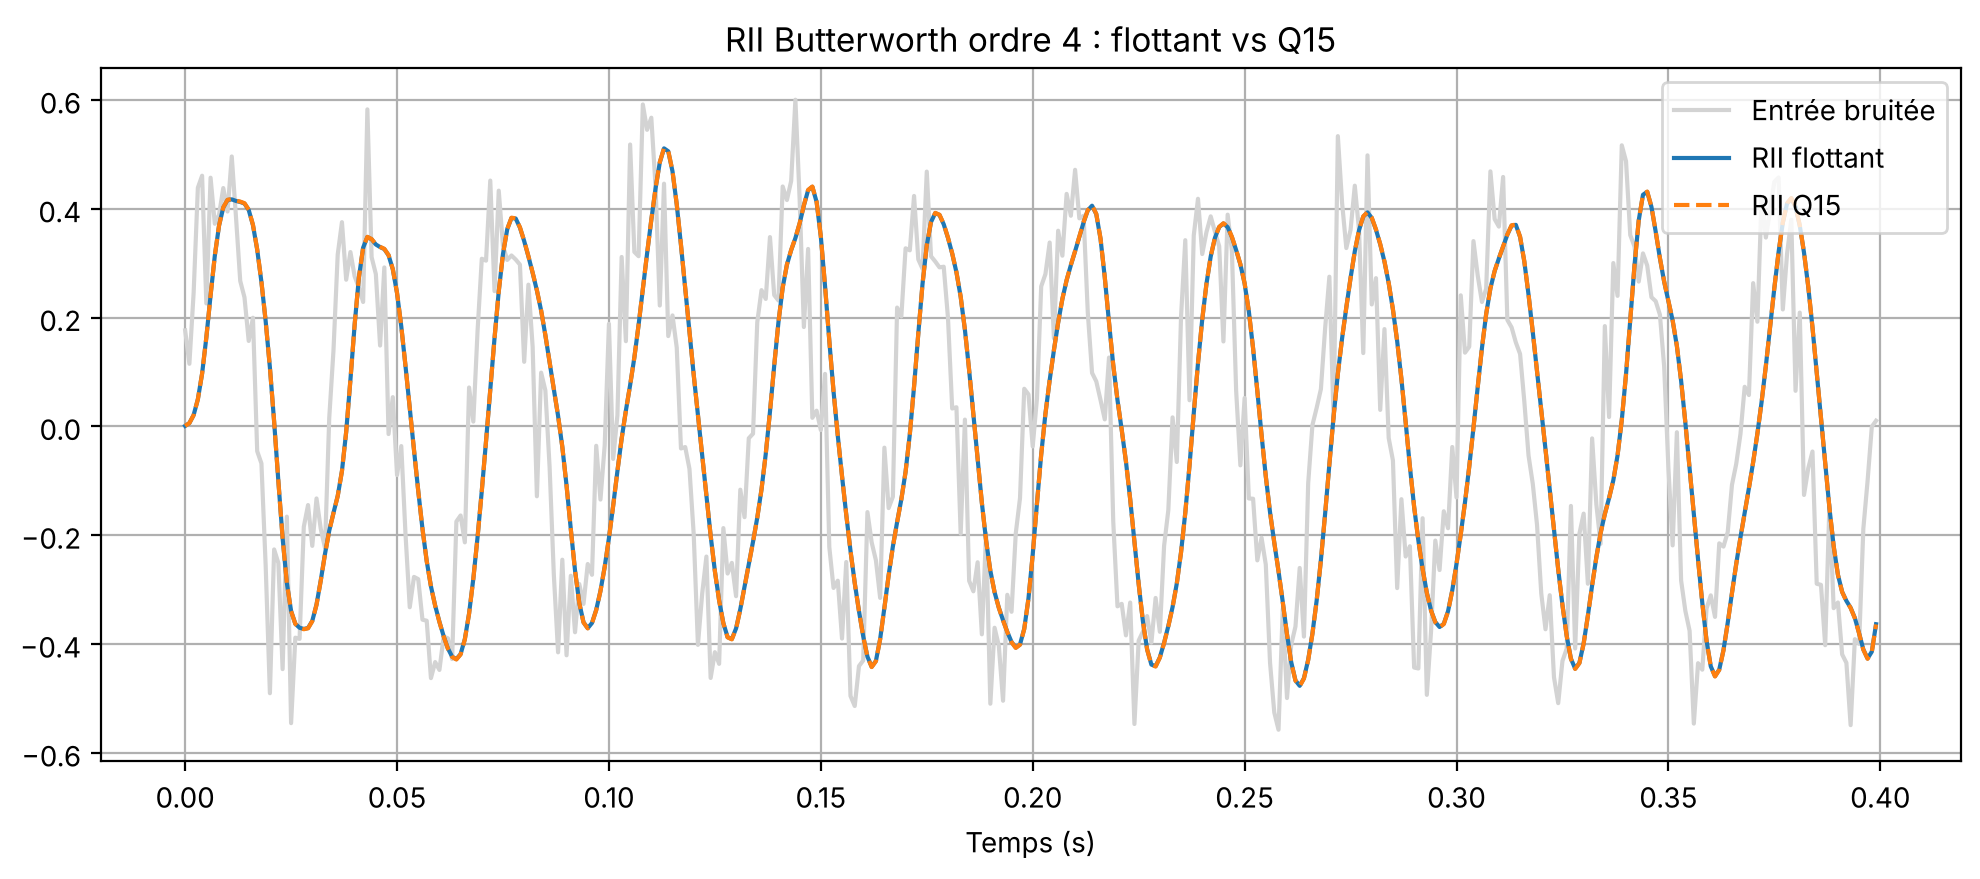

Erreur max flottant vs Q15 : 0.0006

Ordre | rayon max des pôles (double) | rayon max (coefs Q15)
   2  |        0.64250              |   0.64248   stable = True
   4  |        0.79545              |   0.79532   stable = True
   6  |        0.85785              |   0.85859   stable = True
   8  |        0.89121              |   0.89234   stable = True
  10  |        0.91191              |   1.04756   stable = False


In [7]:
# Exercice 1 — Filtre RII Butterworth ordre 4 en Q15 (structure directe II, accumulateur 64 bits)
fs, fc, ordre = 1000, 100, 4
b_f, a_f = signal.butter(ordre, fc, fs=fs, btype='low')
print("b =", np.round(b_f, 5)); print("a =", np.round(a_f, 5))

# Les coefficients du dénominateur dépassent 1 en valeur absolue : le Q15 pur ne suffit pas.
# On utilise un format Q(s).(15-s) commun à b et a : valeur = entier / 2**(15-s)
def choisir_decalage(*listes):
    m = max(np.max(np.abs(l)) for l in listes)
    return max(0, int(np.floor(np.log2(m))) + 1)          # nombre de bits entiers (hors signe)

def quant_coef(coefs, s):
    return np.round(coefs * 2**(15 - s)).astype(np.int32)  # Q(s).(15-s)

s_bits = choisir_decalage(b_f, a_f)
b_q, a_q = quant_coef(b_f, s_bits), quant_coef(a_f, s_bits)
print(f"Format des coefficients : Q{s_bits}.{15-s_bits}  (a1 = {a_q[1]} -> {a_q[1]/2**(15-s_bits):.4f})")

def iir_q15(x_q, b_q, a_q, s):
    """Structure directe II, entrées/sorties Q15 (int16), accumulateur 64 bits.
       w[n] = x[n] - sum a_k w[n-k] ;  y[n] = sum b_k w[n-k]"""
    N, M = len(x_q), len(b_q)
    w = np.zeros(M, dtype=np.int64)          # états (valeurs Q15 sur 64 bits, sans saturation interne)
    y_q = np.zeros(N, dtype=np.int16)
    for n in range(N):
        acc = np.int64(0)
        for k in range(1, M):
            acc += np.int64(a_q[k]) * w[k-1]                 # Q15 * Q(s).(15-s) -> Q(30-s)
        w_n = np.int64(x_q[n]) - ((acc + (1 << (14 - s))) >> (15 - s))
        w = np.concatenate(([w_n], w[:-1]))
        acc = np.int64(0)
        for k in range(M):
            acc += np.int64(b_q[k]) * w[k]
        y = (acc + (1 << (14 - s))) >> (15 - s)
        y_q[n] = np.clip(y, -32768, 32767)                   # saturation de la sortie
    return y_q

# Test sur un signal bruité
np.random.seed(0)
t = np.arange(400) / fs
x_f = 0.4*np.sin(2*np.pi*30*t) + 0.1*np.random.randn(len(t))
y_ref = signal.lfilter(b_f, a_f, x_f)
y_q = q15_to_float(iir_q15(float_to_q15(x_f), b_q, a_q, s_bits))
err = np.max(np.abs(y_ref - y_q))

plt.figure(figsize=(12, 4.5))
plt.plot(t, x_f, color='lightgray', label='Entrée bruitée')
plt.plot(t, y_ref, label='RII flottant')
plt.plot(t, y_q, '--', label='RII Q15')
plt.xlabel('Temps (s)'); plt.legend(); plt.grid(); plt.title('RII Butterworth ordre 4 : flottant vs Q15'); plt.show()
print(f"Erreur max flottant vs Q15 : {err:.4f}")

# Stabilité après quantification des coefficients, en fonction de l'ordre (fc = 100 Hz)
print("\nOrdre | rayon max des pôles (double) | rayon max (coefs Q15)")
for o in [2, 4, 6, 8, 10]:
    bb, aa = signal.butter(o, fc, fs=fs, btype='low')
    ss = choisir_decalage(bb, aa)
    aq = quant_coef(aa, ss) / 2**(15 - ss)
    print(f"  {o:2d}  |        {np.max(np.abs(np.roots(aa))):.5f}              |   {np.max(np.abs(np.roots(aq))):.5f}   stable = {np.max(np.abs(np.roots(aq))) < 1}")

## Interprétation — Exercice 1

- Les coefficients du dénominateur dépassent 1 en valeur absolue : on utilise un format **Q2.13** (2 bits entiers, 13 fractionnaires) au lieu du Q15 pur, et les produits sont accumulés sur **64 bits** avant d'être ramenés en Q15 avec arrondi et saturation.
- La sortie Q15 suit le filtre flottant ; l'erreur maximale est d'environ 0,0006, c'est-à-dire de l'ordre de la précision des coefficients et de l'arrondi à chaque étape.
- **Stabilité** : jusqu'à l'ordre 8, les coefficients quantifiés en Q2.13 laissent tous les pôles dans le cercle unité, mais à l'**ordre 10** le rayon maximal passe de 0,912 à **1,048** : le filtre devient **instable**. Quand l'ordre augmente, les pôles se rapprochent du cercle unité et la forme directe devient de plus en plus **sensible** à l'arrondi des coefficients ; de plus, les états peuvent déborder. C'est pourquoi on implémente les RII d'ordre élevé en **cascade de sections d'ordre 2** (biquads, `arm_biquad_cascade_df1_q15`), avec un décalage de sortie (`postShift`).

## Exercice 2 – FFT en Q15 et fenêtrage

1. Générer un signal composé de deux sinusoïdes de fréquences 120 Hz et 130 Hz, fs=1000 Hz, N=64.
2. Appliquer une fenêtre de Hamming en Q15 (convertir la fenêtre en Q15).
3. Calculer la FFT en Q15 (simulée) et tracer le spectre.
4. Comparer la résolution spectrale avec et sans fenêtre.

**Code** :

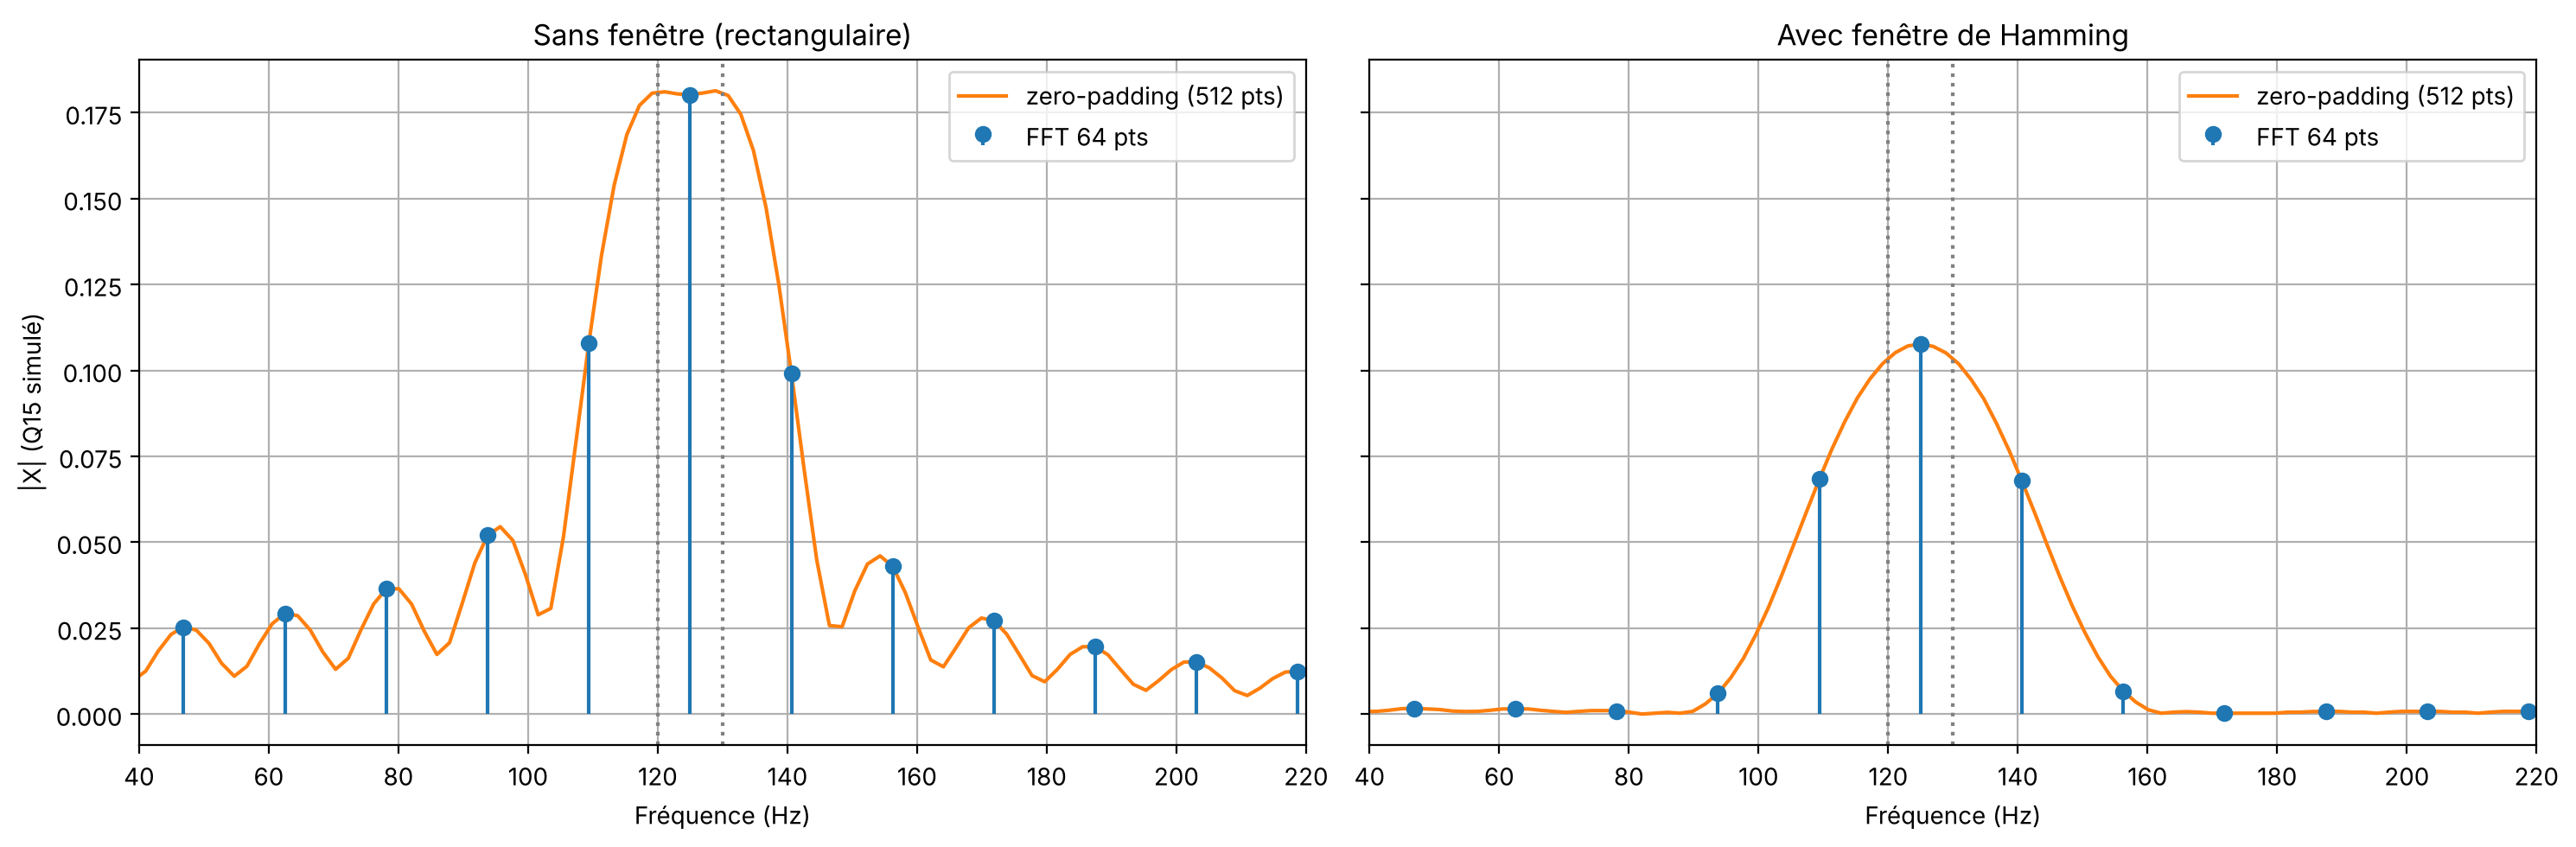

Résolution de la FFT : fs/N = 15.62 Hz ; écart entre les sinusoïdes : 10 Hz
Résolution est donc insuffisante pour séparer 120 Hz et 130 Hz avec N = 64 points.


In [8]:
# Exercice 2 — FFT « Q15 » avec et sans fenêtre de Hamming (deux sinusoïdes 120 Hz et 130 Hz)
fs, N = 1000, 64
n = np.arange(N)
x_f = 0.4*np.sin(2*np.pi*120*n/fs) + 0.4*np.sin(2*np.pi*130*n/fs)
x_q = float_to_q15(x_f)

# Fenêtre de Hamming en Q15 et application avec arrondi : (x*w + 2^14) >> 15
w_q = float_to_q15(np.hamming(N))
xw_q = ((x_q.astype(np.int32) * w_q.astype(np.int32) + (1 << 14)) >> 15).astype(np.int16)

def fft_q15_sim(x_q, nfft):
    """FFT simulée : comme arm_rfft_q15, la sortie est mise à l'échelle par 1/nfft ; résultat requantifié en Q15."""
    X = np.fft.rfft(q15_to_float(x_q), n=nfft) / nfft
    return q15_to_float(float_to_q15(X.real)) + 1j*q15_to_float(float_to_q15(X.imag))

fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for a_, (sig_q, titre) in zip(ax, [(x_q, 'Sans fenêtre (rectangulaire)'), (xw_q, 'Avec fenêtre de Hamming')]):
    X64 = fft_q15_sim(sig_q, N)                         # 64 points : bins de 15,6 Hz
    X512 = fft_q15_sim(sig_q, 512)*8                    # zero-padding x8 pour mieux voir la forme du spectre
    a_.plot(np.fft.rfftfreq(512, 1/fs), np.abs(X512), color='C1', label='zero-padding (512 pts)')
    a_.stem(np.fft.rfftfreq(N, 1/fs), np.abs(X64), basefmt=' ', label='FFT 64 pts')
    a_.axvline(120, color='gray', ls=':'); a_.axvline(130, color='gray', ls=':')
    a_.set_xlim(40, 220); a_.set_xlabel('Fréquence (Hz)'); a_.set_title(titre); a_.grid(); a_.legend()
ax[0].set_ylabel('|X| (Q15 simulé)')
plt.tight_layout(); plt.show()

print(f"Résolution de la FFT : fs/N = {fs/N:.2f} Hz ; écart entre les sinusoïdes : 10 Hz")
print("Résolution est donc insuffisante pour séparer 120 Hz et 130 Hz avec N = 64 points.")

## Interprétation — Exercice 2

- Avec $N = 64$ et $f_s = 1$ kHz, la résolution de la FFT est $f_s/N = 15{,}6$ Hz, alors que les deux sinusoïdes sont séparées de **10 Hz** : elles ne peuvent pas être séparées. On voit **un seul pic élargi**.
- La fenêtre de Hamming **élargit** encore le lobe principal (environ le double de celui de la fenêtre rectangulaire) : la résolution **empire**. En contrepartie, elle réduit fortement les lobes secondaires (fuites spectrales), ce qui est utile quand une raie faible se trouve à côté d'une raie forte.
- Le **zero-padding** (courbe orange) lisse le tracé mais n'ajoute pas d'information : la vraie résolution reste $f_s/N$. Pour séparer 120 Hz et 130 Hz il faudrait $N \ge 100$ échantillons environ (sans fenêtre) ou davantage avec Hamming.
- En Q15, la FFT doit être **mise à l'échelle** ($1/N$ en sortie) pour éviter les débordements, ce qui coûte un peu de précision sur les raies faibles.

## Exercice 3 – Estimation de la consommation mémoire

Pour une application DSP embarquée, on doit estimer la mémoire nécessaire.

1. Un filtre FIR à 64 coefficients en Q15 (int16) est utilisé. Calculer la mémoire pour les coefficients, l'état (buffer circulaire), et le code si nécessaire.
2. Une FFT de 256 points en Q15 nécessite des tables de twiddle factors (rotations). Estimer la mémoire pour ces tables.
3. Proposer une optimisation pour réduire la mémoire (par exemple, utiliser des coefficients symétriques pour le FIR).

In [9]:
# Exercice 3 — Estimation de la mémoire (en octets)
q15 = 2   # octets par échantillon/coefficient Q15 (int16)

# 1. FIR 64 coefficients Q15
coefs = 64 * q15
etat  = 64 * q15                                     # buffer d'état (au minimum numTaps échantillons)
print(f"FIR 64 coefficients : coefficients = {coefs} o, état = {etat} o, total = {coefs+etat} o")

# 2. FFT 256 points Q15
N = 256
twiddle_min = (N//2) * 2 * q15                       # N/2 facteurs de rotation complexes (cos, sin)
buf_fft     = N * 2 * q15                            # buffer complexe en place : N x (re, im)
print(f"FFT {N} points : twiddles (minimum) = {twiddle_min} o, buffer complexe = {buf_fft} o")

# 3. Optimisation : FIR symétrique -> on ne stocke que la moitié des coefficients
coefs_sym = (64//2) * q15
print(f"FIR symétrique : coefficients = {coefs_sym} o (au lieu de {coefs} o), soit {coefs-coefs_sym} o économisés")
total = coefs + etat + twiddle_min + buf_fft
print(f"Total approximatif (données seulement) : {total} o = {total/1024:.2f} Ko")

FIR 64 coefficients : coefficients = 128 o, état = 128 o, total = 256 o
FFT 256 points : twiddles (minimum) = 512 o, buffer complexe = 1024 o
FIR symétrique : coefficients = 64 o (au lieu de 128 o), soit 64 o économisés
Total approximatif (données seulement) : 1792 o = 1.75 Ko


### 📝 Réponse — Exercice 3

1. **FIR 64 coefficients en Q15** : coefficients $64 \times 2 = 128$ octets ; buffer d'état $\ge 64 \times 2 = 128$ octets (CMSIS-DSP demande `numTaps + blockSize − 1` échantillons) ; le code est en Flash, à part.
2. **FFT 256 points en Q15** : une table de $N/2 = 128$ facteurs de rotation **complexes** (cos et sin) occupe au minimum $128 \times 2 \times 2 = 512$ octets. Chaque facteur a **deux** composantes : l'estimation « $N/2 \times 2 = 256$ octets » de l'énoncé est donc trop faible. La bibliothèque CMSIS-DSP stocke en général une table plus grande que ce minimum. Il faut en plus un buffer complexe de travail : $256 \times 2 \times 2 = 1024$ octets.
3. **Optimisations** : FIR **symétrique** (32 coefficients stockés, soit 64 octets économisés) ; FFT **réelle** (`arm_rfft_q15`), qui traite $N$ échantillons réels avec une FFT complexe de $N/2$ points ; **table de twiddle partagée** entre plusieurs FFT ; tables placées en **Flash** plutôt qu'en RAM.

## Exercice 4 – Proposition de projet final

Rédiger une proposition de projet intégrant du DSP sur STM32 avec CMSIS‑DSP. La proposition doit inclure :
- Objectif du projet (ex : analyse de signaux ECG, traitement audio, contrôle moteur).
- Spécifications techniques (fréquence d'échantillonnage, nombre de canaux, type de traitement).
- Choix des algorithmes (filtres, FFT, etc.) et justification.
- Estimation des ressources (temps de calcul, mémoire).
- Plan de développement.

**Rédiger la proposition dans une cellule Markdown.**

### Proposition de projet — Surveillance de vibrations d'un moteur par FFT sur STM32

**Objectif.** Détecter un défaut naissant (balourd, désalignement, roulement usé) sur un petit moteur en analysant le spectre de ses vibrations en temps réel, et signaler une alarme quand l'énergie dans certaines raies dépasse un seuil.

**Spécifications techniques.**
- Capteur : accéléromètre 3 axes (MEMS), lu par SPI ou I²C.
- Fréquence d'échantillonnage $f_s = 2$ kHz par axe (bande utile jusqu'à 1 kHz ; critère de Nyquist respecté, anti-repliement analogique ou filtre numérique intégré au capteur).
- Fenêtre d'analyse : $N = 1024$ échantillons, soit 0,512 s et une résolution $f_s/N \approx 1{,}95$ Hz.
- Sortie : spectre d'amplitude, fréquence et amplitude des 3 raies dominantes, indicateur d'alarme.

**Algorithmes et justification.**
1. **Filtre passe-haut RII** (Butterworth ordre 2, ~5 Hz) en cascade de biquads : supprime la composante continue (gravité) et les dérives, pour un coût très faible.
2. **Fenêtre de Hann** : réduit les fuites spectrales pour mesurer correctement des raies d'amplitudes très différentes.
3. **FFT réelle** (`arm_rfft_fast_f32` ou `arm_rfft_q15`) : donne directement le contenu fréquentiel, qui est le critère de diagnostic.
4. **Seuil sur l'énergie par bande** : décision simple, facile à régler.

**Estimation des ressources.**
- Mémoire de données (flottant 32 bits) : $3 \times 1024 \times 4 \approx 12$ Ko pour les buffers, plus les tables de la FFT.
- Calcul : les durées sont à **mesurer sur la carte** (compteur de cycles DWT). On attend quelques millisecondes pour 3 FFT de 1024 points sur un Cortex-M4, très inférieur aux 512 ms disponibles entre deux fenêtres.

**Plan de développement.**
1. Simulation complète sous Python (signaux synthétiques avec défaut, choix du filtre, de la fenêtre et du seuil).
2. Portage en C avec CMSIS-DSP et validation sur les mêmes signaux (comparaison flottant / Q15).
3. Acquisition réelle du capteur, mesure du temps de calcul et de la mémoire.
4. Essais sur un moteur, réglage des seuils, rédaction du compte rendu.

## Exercice 5 – Simulation d'une application temps réel

On souhaite simuler un traitement temps réel sur un microcontrôleur. On considère un buffer circulaire de 128 échantillons, un filtre FIR de 31 coefficients, et une FFT de 128 points.

1. Écrire un code Python qui simule le traitement en continu : chaque itération, on ajoute un nouvel échantillon, on met à jour le buffer, on applique le filtre et on calcule la FFT sur les 128 derniers échantillons.
2. Mesurer le temps d'exécution de chaque étape (utiliser `time.perf_counter`).
3. Estimer si un Cortex-M4 à 100 MHz peut respecter une période d'échantillonnage de 1 ms.
4. Proposer des optimisations (ex : utiliser la FFT uniquement tous les N échantillons).

**Code** :

In [10]:
# Exercice 5 — Simulation temps réel : buffer circulaire + FIR + FFT
import time
fs = 1000
buffer_size = 128
buffer = np.zeros(buffer_size)
idx = 0                                   # indice d'écriture du buffer circulaire
b_fir = signal.firwin(31, 150, fs=fs, window='hamming')

t_buf, t_fir, t_fft = [], [], []
np.random.seed(0)
n_iter = 400
for n in range(n_iter):
    new_sample = np.sin(2*np.pi*80*n/fs) + 0.1*np.random.randn()   # échantillon simulé (ADC)

    t0 = time.perf_counter()
    buffer[idx] = new_sample                                    # écriture circulaire (pas de décalage de tout le tableau)
    idx = (idx + 1) % buffer_size
    t1 = time.perf_counter()

    last = np.concatenate((buffer[idx:], buffer[:idx]))         # 128 derniers échantillons dans l'ordre
    y_n = np.dot(b_fir, last[::-1][:len(b_fir)])                # une sortie du FIR (31 MAC)
    t2 = time.perf_counter()

    spectre = np.abs(np.fft.rfft(last))                         # FFT sur 128 points
    t3 = time.perf_counter()

    t_buf.append(t1 - t0); t_fir.append(t2 - t1); t_fft.append(t3 - t2)

tb, tf, tt = (np.median(v)*1e6 for v in (t_buf, t_fir, t_fft))
print(f"Temps médian Python par itération : buffer = {tb:.1f} µs, FIR = {tf:.1f} µs, FFT = {tt:.1f} µs")
print(f"Fréquence du pic de la dernière FFT : {np.argmax(spectre)*fs/buffer_size:.1f} Hz  (attendu : ~80 Hz)")

# Estimation du budget sur un Cortex-M4 à 100 MHz (hypothèses de coût en cycles, à vérifier par mesure sur la carte)
f_cpu = 100e6
periode = 1e-3                                 # fs = 1 kHz
budget_cycles = f_cpu * periode
cycles_fir = 31 * 2                            # ~2 cycles par MAC (instruction SMLAD possible : moins)
cycles_fft = 20_000                            # hypothèse prudente pour une FFT 128 points Q15
print(f"\nBudget par échantillon : {budget_cycles:,.0f} cycles")
print(f"FIR (hypothèse)         : {cycles_fir:,} cycles  ({100*cycles_fir/budget_cycles:.2f} % du budget)")
print(f"FFT à chaque échantillon : {cycles_fft:,} cycles  ({100*cycles_fft/budget_cycles:.1f} % du budget)")
print(f"FFT tous les 64 échantillons : {cycles_fft/64:,.0f} cycles en moyenne ({100*cycles_fft/64/budget_cycles:.2f} %)")

Temps médian Python par itération : buffer = 0.2 µs, FIR = 2.5 µs, FFT = 5.3 µs
Fréquence du pic de la dernière FFT : 78.1 Hz  (attendu : ~80 Hz)

Budget par échantillon : 100,000 cycles
FIR (hypothèse)         : 62 cycles  (0.06 % du budget)
FFT à chaque échantillon : 20,000 cycles  (20.0 % du budget)
FFT tous les 64 échantillons : 312 cycles en moyenne (0.31 %)


## Interprétation — Exercice 5

- Sur le PC, chaque étape prend quelques microsecondes à quelques dizaines de microsecondes : ces valeurs ne se transposent pas telles quelles au microcontrôleur, mais elles montrent que la **FFT est de loin l'étape la plus coûteuse** (FIR : 31 MAC, FFT : de l'ordre de $N \log_2 N$ opérations).
- **Budget Cortex-M4 à 100 MHz** : 1 ms par échantillon = **100 000 cycles**. Avec nos hypothèses de coût, le FIR en prend moins de 0,1 % et même une FFT à chaque échantillon (20 000 cycles) tient dans le budget, avec une marge de l'ordre de 80 %. La contrainte temps réel est donc **respectée**.
- **Optimisations** : calculer la FFT seulement tous les 64 échantillons (recouvrement de 50 %), utiliser un buffer circulaire (pas de décalage des données), la FFT réelle, et le DMA pour l'acquisition afin de ne pas mobiliser le CPU.
- Les coûts en cycles sont des **hypothèses** : il faut les mesurer sur la carte (compteur DWT) pour valider.

# 5. Livrable Semaine 11

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---